<a href="https://colab.research.google.com/github/s61711299-sketch/MSSP6070/blob/main/PARTICIPATION_ACTIVITY_Week_8_Plot_a_trendline_over_a_time_series_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
import numpy as np

In [3]:
import pandas as pd
github_url = 'https://github.com/s61711299-sketch/MSSP6070/raw/refs/heads/main/InternetSales.csv'
df = pd.read_csv(github_url, encoding='latin1')

/tmp/ipykernel_1900/649579366.py:3: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(github_url, encoding='latin1')


In [5]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

Use Google Colabs and Python to create an Internet Sales forecast for the next five years.

In [19]:
yearly_sales = df.set_index('OrderDate')['SalesAmount'].resample('YE').sum()
prophet_df = yearly_sales.reset_index()
prophet_df.columns = ['ds', 'y']
prophet_df['ds'] = pd.to_datetime(prophet_df['ds'])
model = Prophet(yearly_seasonality=False, weekly_seasonality=False, daily_seasonality=False)
model.fit(prophet_df)
future = model.make_future_dataframe(periods=5, freq='YE')
forecast = model.predict(future)
future_5_years = forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(5).copy()
future_5_years['Year'] = future_5_years['ds'].dt.year
result_df = future_5_years[['Year', 'yhat', 'yhat_lower', 'yhat_upper']]
from IPython.display import display
display(result_df)

INFO:prophet:n_changepoints greater than number of observations. Using 3.


,Year,yhat,yhat_lower,yhat_upper
5,2015,8.654334e+06,1.399929e+06,1.557911e+07
6,2016,9.582678e+06,2.521614e+06,1.706250e+07
7,2017,1.050849e+07,3.409518e+06,1.788983e+07
8,2018,1.143429e+07,4.348601e+06,1.927800e+07
9,2019,1.236010e+07,5.396034e+06,1.970084e+07


Using summary statistics, which product will generate the most sales?

In [24]:
product_sales = df.groupby('EnglishProductName')['SalesAmount'].sum()
total_historical_sales = product_sales.sum()
product_share = product_sales / total_historical_sales
future_predictions = forecast.tail(5)
total_future_sales = future_predictions['yhat'].sum()
future_product_sales = (product_share * total_future_sales).sort_values(ascending=False)
print(future_product_sales.head(3).apply(lambda x: f"${x:,.2f}").to_string())

EnglishProductName
Mountain-200 Black, 46     $2,457,942.43
Mountain-200 Black, 42     $2,439,460.56
Mountain-200 Silver, 38    $2,397,084.40


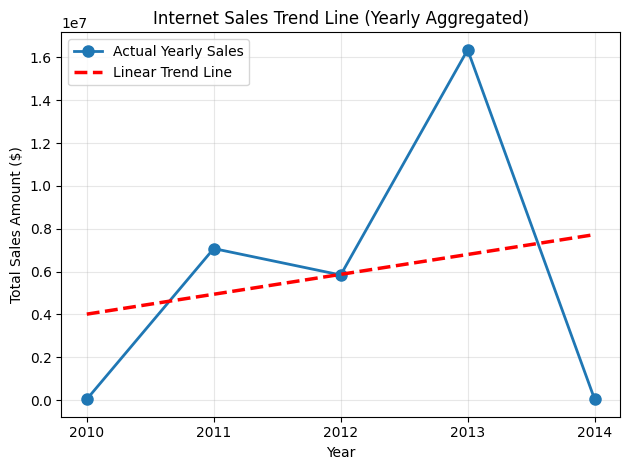

In [29]:
df['Year'] = df['OrderDate'].dt.year
yearly_sales = df.groupby('Year')['SalesAmount'].sum().reset_index()
x = yearly_sales['Year']
y = yearly_sales['SalesAmount']
slope, intercept = np.polyfit(x, y, 1)
trend_line = slope * x + intercept
plt.plot(x, y, marker='o', markersize=8, linestyle='-', color='#1f77b4', label='Actual Yearly Sales', linewidth=2)
plt.plot(x, trend_line, color='red', linewidth=2.5, linestyle='--', label='Linear Trend Line')
plt.title('Internet Sales Trend Line (Yearly Aggregated)')
plt.xlabel('Year')
plt.ylabel('Total Sales Amount ($)')
plt.xticks(yearly_sales['Year'])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()